<h1 align = "center">
Rwanda Maize-Urea Trial
</h1>

<h2 align = "center">
Exploratory Data Analysis
</h2> 

# Objective

- The goal here is to begin answering the research question: **How do maize yields vary across Urea treatment combinations, seasons and mega-environments?** 

    - We want to start with the simplest and most important view: yield distribution by treatment. 

    - This should establish the baseline before we investigate environmental variation or perform statistical tests.


## Imports and Setups

In [9]:
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings("ignore")

In [10]:
from pathlib import Path

# Defining path to folder
data_path = Path(r"../01_data/processed")

def load_csv (filename):
    return pd.read_csv(data_path/filename)

In [11]:
integrated_df = load_csv("plot_with_field_soil.csv")
integrated_df.head()

,block_id,season,plot_id,treat_code,treat_details,urea_rate_timing,crop,prior_season_crop,planting_date,compost_tha,...,check_planting_date_before_harvest_date,days_silking_to_R3,calculated_urea_total,urea_total_difference,meg_env,_merge,pH,soil_match,has_soil_record,has_field_match
0,adfa31ad-95bf-453d-94f1-d163a97756ee,21A,adfa31ad-95bf-453d-94f1-d163a97756ee-21A-A,A,DAP 1Kg/Are + Urea 0.5Kg/Are at V6,Urea 0.5Kg/Are(V6),maize,maize,9/26/2020,8,...,False,20.0,50,0,Low-Mid-Dry,both,5.21,both,True,True
1,adfa31ad-95bf-453d-94f1-d163a97756ee,21A,adfa31ad-95bf-453d-94f1-d163a97756ee-21A-B,B,DAP 1Kg/Are + Urea 0.5Kg/Are at Planting and U...,Urea1kg/Are(Planting+V6),maize,maize,9/26/2020,8,...,False,20.0,100,0,Low-Mid-Dry,both,NaN,left_only,False,True
2,adfa31ad-95bf-453d-94f1-d163a97756ee,21A,adfa31ad-95bf-453d-94f1-d163a97756ee-21A-C,C,DAP 1Kg/Are + Urea 0.5Kg/Are at V6 + Urea 0.5K...,Urea 1kg/Are(V6 + V10),maize,maize,9/26/2020,8,...,False,20.0,100,0,Low-Mid-Dry,both,NaN,left_only,False,True
3,adfa31ad-95bf-453d-94f1-d163a97756ee,21A,adfa31ad-95bf-453d-94f1-d163a97756ee-21A-D,D,DAP 1Kg/Are at planting+ Urea 1Kg/Are at V6,Urea 1kg/Are(V6),maize,maize,9/26/2020,8,...,False,20.0,100,0,Low-Mid-Dry,both,NaN,left_only,False,True
4,d8807f25-e675-49ae-87a3-d228eca23c72,21A,d8807f25-e675-49ae-87a3-d228eca23c72-21A-A,A,DAP 1Kg/Are + Urea 0.5Kg/Are at V6,Urea 0.5Kg/Are(V6),maize,maize,9/26/2020,10,...,False,20.0,50,0,Low-Mid-Dry,both,5.75,both,True,True


**What are we looking for?**

- **Mean and median:** Which treatments have higher observed yields?

- **Spread:** Which treatments show more variability?

- **Overlap:** Are the yield distributions substantially overlapping, or do some treatments appear more distinct?

- **Outliers:** Are there unusually low or high yields worth noting without automatically removing them?

>Note: These are descriptive comparisons. Because plots are grouped within fields and observed across different seasons and environments, we should not yet interpret a higher mean as proof that a treatment caused higher yields.

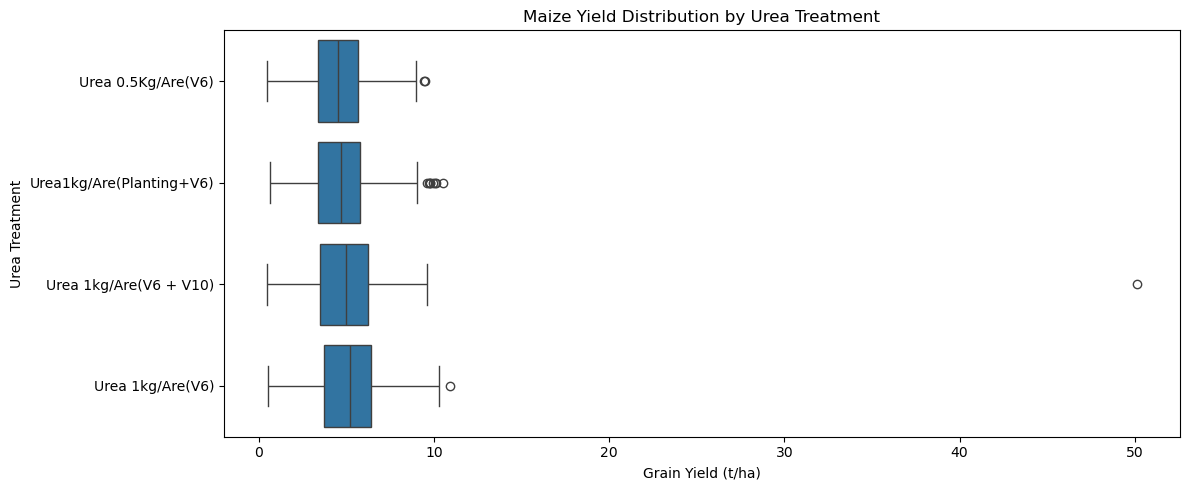

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=integrated_df,
    x="yield_tha",
    y="urea_rate_timing"
)

plt.title("Maize Yield Distribution by Urea Treatment")
plt.xlabel("Grain Yield (t/ha)")
plt.ylabel("Urea Treatment")
plt.tight_layout()
plt.show()

In [13]:
# Summary statistics
treatment_yield_summary = (
    integrated_df
    .groupby("urea_rate_timing")["yield_tha"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
    .sort_values("mean", ascending=False)
)

display(treatment_yield_summary)

,count,mean,median,std,min,max
urea_rate_timing,,,,,,
Urea 1kg/Are(V6),401,5.11,5.22,1.92,0.55,10.90
Urea 1kg/Are(V6 + V10),401,5.06,4.97,2.92,0.49,50.10
Urea1kg/Are(Planting+V6),397,4.71,4.68,1.88,0.63,10.52
Urea 0.5Kg/Are(V6),399,4.57,4.55,1.76,0.49,9.50


We already see a few observations standing out:

- All Urea at V6 has the highest mean and median yield. Its mean is 0.54 t/ha higher than the 50 kg/ha treatment, a descriptive difference of approximately 11.8% relative to the lower-rate treatment.

- Splitting 100 kg/ha between V6 and V10 has a similar mean, at 5.06 t/ha, but noticeably greater variability.

- Splitting 100 kg/ha between planting and V6 has a lower observed mean than applying the full amount at V6.

- The 50 kg/ha treatment has the lowest mean, although its yield distribution may overlap considerably with those of the other treatments.

These are descriptive results across all seasons and environments combined. They do not yet establish that the differences are caused by the treatment itself.

### Treatment yields Comparison by Season

We want to compare the four Urea treatments across the three seasons: 21A, 22A, and 22B. 
- This should help us see whether the overall yield rankings are consistent or whether treatment performance varies by season.

We'll calculate mean yield, median yield, variability, and sample size for each treatment-season combination, then visualize the mean yields.

**What are we looking for?**

- **mean:** average yield for each treatment in each season.

- **median:** helps us see whether unusually high or low observations distort the average.

- **std:** shows how much yields vary within each group.

- **count:** confirms how many observed plots contribute to each summary.

In [14]:
season_treatment_summary = (
    integrated_df
    .groupby(
        ["season", "urea_rate_timing"],
        observed=True
    )
    ["yield_tha"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .round(2)
    .reset_index()
    .sort_values(["season", "mean"], ascending=[True, False])
)

display(season_treatment_summary)

,season,urea_rate_timing,count,mean,median,std
2,21A,Urea 1kg/Are(V6),128,4.85,4.78,1.80
1,21A,Urea 1kg/Are(V6 + V10),128,4.78,4.88,1.76
3,21A,Urea1kg/Are(Planting+V6),126,4.43,4.40,1.68
0,21A,Urea 0.5Kg/Are(V6),127,4.30,4.39,1.59
6,22A,Urea 1kg/Are(V6),193,5.39,5.44,2.03
5,22A,Urea 1kg/Are(V6 + V10),193,5.19,5.40,1.98
7,22A,Urea1kg/Are(Planting+V6),192,5.05,5.06,2.03
4,22A,Urea 0.5Kg/Are(V6),193,4.89,4.71,1.91
9,22B,Urea 1kg/Are(V6 + V10),80,5.22,4.82,5.33
10,22B,Urea 1kg/Are(V6),80,4.84,5.12,1.73


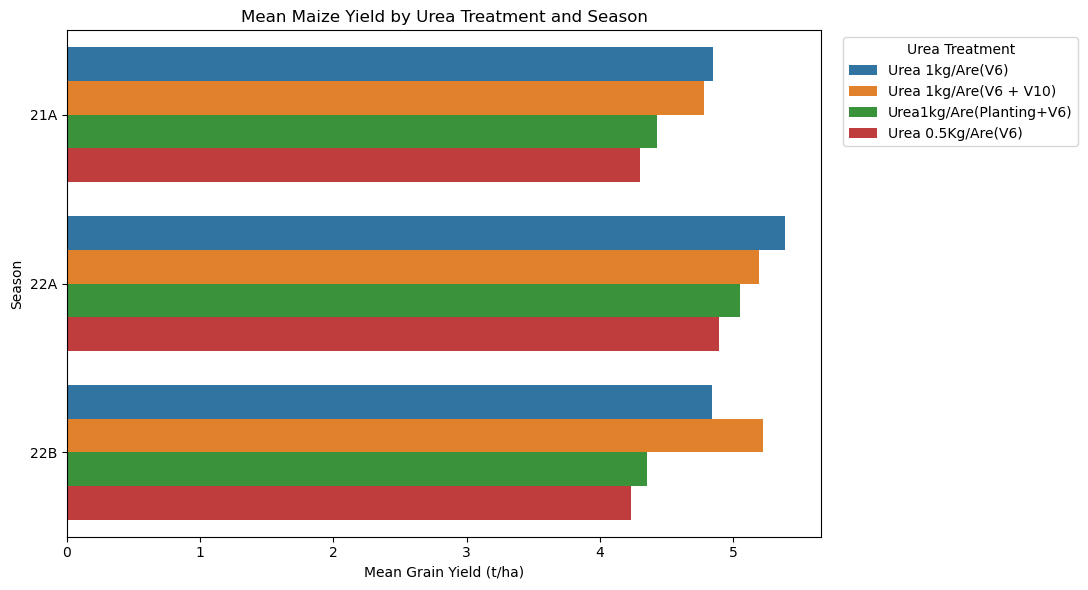

In [15]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=season_treatment_summary,
    x="mean",
    y="season",
    hue="urea_rate_timing",
    errorbar=None
)

plt.title("Mean Maize Yield by Urea Treatment and Season")
plt.xlabel("Mean Grain Yield (t/ha)")
plt.ylabel("Season")
plt.legend(
    title="Urea Treatment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

### **Results**

Our season-by-season results reveal a fairly consistent pattern: 

- applying the full 100 kg/ha of Urea at V6 has the highest mean yield in seasons 21A and 22A, while 

- splitting the same rate between V6 and V10 has the highest mean in 22B.

There are two findings worth carrying forward: 

- the overall treatment ranking is broadly similar across seasons, and 

- the V6 + V10 treatment has unusually high variability in 22B.

### What does this tell us then?

**Season 21A:** n ≈ 126 - 128 per treatment : *4.85 t/ha*

Highest mean: 100 kg/ha, all at V6

- The V6-only treatment narrowly leads the V6 + V10 split (4.78 t/ha). The 100 kg/ha planting + V6 treatment averages 4.43 t/ha, while the 50 kg/ha V6 treatment averages 4.30 t/ha.

**Season 22A:** n ≈ 192 - 193 per treatment : *5.39 t/ha*

Highest mean: 100 kg/ha, all at V6

- This is the clearest descriptive advantage for V6-only application. Its mean is 0.20 t/ha above V6 + V10 and 0.50 t/ha above planting + V6.

**Season 22B:** n ≈ 79 - 80 per treatment : *5.22 t/ha*

Highest mean: 100 kg/ha, split V6 + V10

- The V6 + V10 treatment leads the V6-only treatment (4.84 t/ha) by 0.38 t/ha. However, its standard deviation is 5.33 t/ha, much larger than those of the other treatments.

#### **Emerging patterns**

- The full 100 kg/ha at V6 performs consistently well. It has the highest mean in two of the three seasons.

- The lower Urea rate has the lowest mean in every season. That is consistent with a possible benefit from the higher rate, but timing and rate are not isolated by every comparison.

- The planting + V6 split does not lead in any season. Its mean is below the V6-only treatment in all three seasons.

- Season 22B deserves caution. The V6 + V10 mean (5.22) exceeds its median (4.82), and its standard deviation (5.33) is unusually large. This suggests that one or more high yields may be influencing its mean. We should not conclude that the split treatment performs better in 22B without accounting for that variability.

> These are only observed differences, not yet statistically established treatment effects.

### Treatment Performance by Mega Environment

Before we embark on formal statistical testing, we want to make one essential comparison that is directly relevant to the overall research objective. 

- Since the trial spans different mega-environments, pooling all fields within a season could conceal differences in how treatments perform under different growing conditions.

In [16]:
me_treatment_summary = (
    integrated_df
    .dropna(subset=["meg_env"])
    .groupby(
        ["meg_env", "urea_rate_timing"],
        observed=True
    )
    ["yield_tha"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .round(2)
    .reset_index()
    .sort_values(["meg_env", "mean"], ascending=[True, False])
)

display(me_treatment_summary)

,meg_env,urea_rate_timing,count,mean,median,std
2,Highlands,Urea 1kg/Are(V6),142,4.66,4.77,1.91
1,Highlands,Urea 1kg/Are(V6 + V10),142,4.54,4.72,1.83
3,Highlands,Urea1kg/Are(Planting+V6),139,4.29,4.25,1.78
0,Highlands,Urea 0.5Kg/Are(V6),142,4.18,4.03,1.81
5,Low-Mid-Dry,Urea 1kg/Are(V6 + V10),115,6.42,6.17,4.44
6,Low-Mid-Dry,Urea 1kg/Are(V6),115,6.19,6.21,1.85
7,Low-Mid-Dry,Urea1kg/Are(Planting+V6),115,5.77,5.54,1.93
4,Low-Mid-Dry,Urea 0.5Kg/Are(V6),115,5.69,5.63,1.65
10,Low-Mid-Wet,Urea 1kg/Are(V6),77,4.70,4.87,1.69
9,Low-Mid-Wet,Urea 1kg/Are(V6 + V10),77,4.67,4.76,1.80


### Interpretation

What we have here is a usefulpicture of how Urea treatment performance varies across Rwanda's four mega-environments.

- We see that applying 100 kg/ha of Urea entirely at V6 has the highest mean yield in three of the four mega-environments. In Low-Mid-Dry, splitting the application between V6 and V10 has the highest mean.

1. **Treatment performance by mega-environment**

|Mega-environment	|Highest mean-yield treatment	|Mean yield (t/ha)
|----|----|----
|Highlands	|100 kg/ha, all at V6	|4.66
|Low-Mid-Dry	|100 kg/ha, split V6 + V10	|6.42
|Low-Mid-Wet	|100 kg/ha, all at V6	|4.70
|Transitional	|100 kg/ha, all at V6	|4.71

**So what stands out?**

- **Highlands:** The V6-only treatment leads the V6 + V10 treatment by 0.12 t/ha. The differences between treatments are relatively modest.

- **Low-Mid-Dry:** This environment has the highest observed yields. The V6 + V10 treatment leads V6-only by 0.23 t/ha, but its standard deviation of 4.44 t/ha is unusually high compared with the other treatments. 

Its mean should therefore be interpreted cautiously.

- **Low-Mid-Wet:** V6-only leads V6 + V10 by just 0.03 t/ha. These means are nearly identical descriptively.

- **Transitional:** V6-only leads V6 + V10 by 0.39 t/ha, the largest gap between those two treatments among the four environments.

The 50 kg/ha treatment has the lowest mean yield in three environments. Transitional is the exception: its mean of 4.25 t/ha is marginally higher than the planting + V6 split at 4.24 t/ha.

**What does this mean for the research question?**

The results suggest two patterns worth testing formally:

1. **Treatment pattern:** *Applying the full 100 kg/ha at V6 appears to be a consistently strong option across environments.*

2. **Environment-specific response:** *The V6 + V10 split leads in Low-Mid-Dry, suggesting that the best-performing treatment may depend on the growing environment.*

These are hypotheses generated by descriptive analysis, not proof of treatment effects. In particular, we'll avoid recommending a different treatment for Low-Mid-Dry based solely on its mean, given the unusually high variability.

> *We can say we've now compared yields by treatment overall, season, and mega-environment. That's enough descriptive analysis to motivate the next stage; we don't need more layers of summaries.*